# Detecção de Evasão no Ensino Superior

Este notebook apresenta, de forma estática, um MVP para identificar estudantes com risco de evasão. A análise compara três momentos de previsão: **matrícula**, **após o 1º semestre** e **após o 2º semestre**.

A classe `Enrolled` é removida porque representa uma trajetória ainda não definida. O alvo passa a ser binário: `1` para evasão e `0` para graduação.

In [9]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style="whitegrid", palette="deep")
RANDOM_STATE = 42
DATA_PATH = Path("data") / "data.csv"
if not DATA_PATH.exists():
    DATA_PATH = Path("..") / "data" / "data.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {DATA_PATH.resolve()}")

df = pd.read_csv(DATA_PATH, sep=";")
df.columns = df.columns.str.replace("\t", " ", regex=False).str.strip()
nomes_variaveis_pt = {
    "Marital status": "Estado civil",
    "Application mode": "Modalidade de ingresso",
    "Application order": "Ordem de ingresso",
    "Course": "Curso",
    "Daytime/evening attendance": "Turno (diurno/noturno)",
    "Previous qualification": "Qualificação anterior",
    "Previous qualification (grade)": "Nota da qualificação anterior",
    "Nacionality": "Nacionalidade",
    "Mother's qualification": "Qualificação da mãe",
    "Father's qualification": "Qualificação do pai",
    "Mother's occupation": "Ocupação da mãe",
    "Father's occupation": "Ocupação do pai",
    "Admission grade": "Nota de admissão",
    "Displaced": "Aluno deslocado",
    "Educational special needs": "Necessidades educacionais especiais",
    "Debtor": "Devedor",
    "Tuition fees up to date": "Mensalidades em dia",
    "Gender": "Gênero",
    "Scholarship holder": "Bolsista",
    "Age at enrollment": "Idade na matrícula",
    "International": "Estudante internacional",
    "Curricular units 1st sem (credited)": "Unidades curriculares 1º sem. (creditadas)",
    "Curricular units 1st sem (enrolled)": "Unidades curriculares 1º sem. (matriculadas)",
    "Curricular units 1st sem (evaluations)": "Unidades curriculares 1º sem. (avaliadas)",
    "Curricular units 1st sem (approved)": "Unidades curriculares 1º sem. (aprovadas)",
    "Curricular units 1st sem (grade)": "Nota média 1º semestre",
    "Curricular units 1st sem (without evaluations)": "Unidades curriculares 1º sem. (sem avaliação)",
    "Curricular units 2nd sem (credited)": "Unidades curriculares 2º sem. (creditadas)",
    "Curricular units 2nd sem (enrolled)": "Unidades curriculares 2º sem. (matriculadas)",
    "Curricular units 2nd sem (evaluations)": "Unidades curriculares 2º sem. (avaliadas)",
    "Curricular units 2nd sem (approved)": "Unidades curriculares 2º sem. (aprovadas)",
    "Curricular units 2nd sem (grade)": "Nota média 2º semestre",
    "Curricular units 2nd sem (without evaluations)": "Unidades curriculares 2º sem. (sem avaliação)",
    "Unemployment rate": "Taxa de desemprego",
    "Inflation rate": "Taxa de inflação",
    "GDP": "PIB",
    "Alvo": "Evasão"
}
print(f"Dimensões originais: {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"Colunas normalizadas: {list(df.columns)}")

Dimensões originais: 4424 linhas x 37 colunas
Colunas normalizadas: ['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', '

### Comentário sobre a leitura da base

- **O que foi feito:** o arquivo `data.csv` foi carregado, os nomes das colunas foram padronizados e o tamanho da base foi exibido.
- **Por que isso foi feito:** a padronização evita erros ao acessar colunas, enquanto as dimensões confirmam se os dados foram lidos corretamente.
- **Conclusão:** a base possui **4.424 registros e 37 colunas** e está pronta para as próximas etapas.

In [10]:
if "Target" not in df.columns:
    raise KeyError("A coluna obrigatória 'Target' não foi encontrada.")

df = df.loc[df["Target"].isin(["Dropout", "Graduate"])].copy()
df["Alvo"] = df["Target"].map({"Dropout": 1, "Graduate": 0}).astype("int8")
df = df.drop(columns="Target")

features_matricula = [
    col for col in df.columns
    if col not in ["Alvo"] and "1st sem" not in col.lower() and "2nd sem" not in col.lower()
]
features_1o_semestre = [
    col for col in df.columns
    if col != "Alvo" and "2nd sem" not in col.lower()
]
features_2o_semestre = [col for col in df.columns if col != "Alvo"]

cenarios = {
    "Matrícula": features_matricula,
    "1º semestre": features_1o_semestre,
    "2º semestre": features_2o_semestre,
}

print(f"Registros definitivos: {len(df)}")
print(f"Evasão: {df['Alvo'].sum()} | Não evasão: {(df['Alvo'] == 0).sum()}")
for nome, features in cenarios.items():
    print(f"{nome}: {len(features)} variáveis")

Registros definitivos: 3630
Evasão: 1421 | Não evasão: 2209
Matrícula: 24 variáveis
1º semestre: 30 variáveis
2º semestre: 36 variáveis


### Comentário sobre a preparação dos dados

- **O que foi feito:** foram removidos registros sem resultado definitivo, o alvo foi convertido para `1` (evasão) ou `0` (não evasão), e foram criados três cenários de previsão.
- **Por que isso foi feito:** o modelo precisa de uma variável-alvo clara e de conjuntos de atributos compatíveis com o momento em que a previsão seria realizada.
- **Conclusão:** restaram **3.630 estudantes**, sendo **1.421 em evasão** e **2.209 sem evasão**. Quanto mais informações do semestre estão disponíveis, mais variáveis podem ser usadas.

## 1. Dashboard estático: visão geral da base

Os gráficos abaixo são gerados no próprio notebook e constituem uma apresentação estática dos resultados.

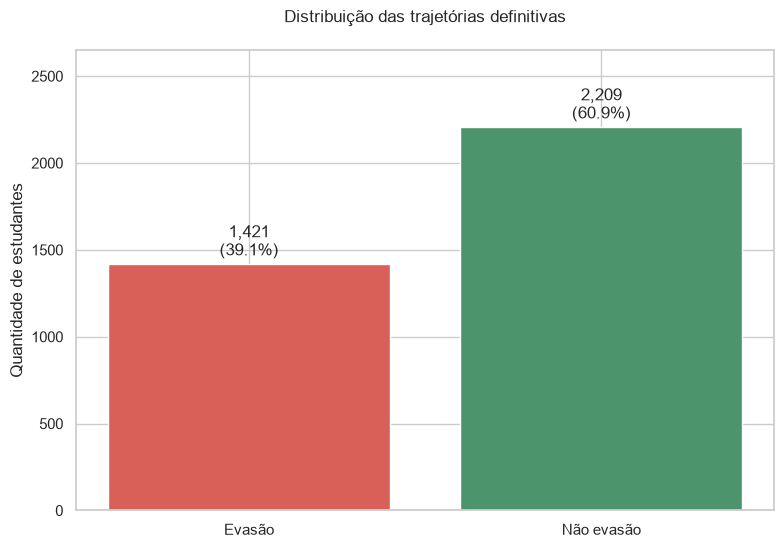

,Quantidade,Percentual (%)
Alvo,,
Evasão,1421,39.15
Não evasão,2209,60.85


In [11]:
contagem = df["Alvo"].map({0: "Não evasão", 1: "Evasão"}).value_counts().reindex(["Evasão", "Não evasão"])
percentual = contagem / contagem.sum() * 100

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(contagem.index, contagem.values, color=["#d95f59", "#4c956c"])
ax.set_title("Distribuição das trajetórias definitivas", pad=20)
ax.set_ylabel("Quantidade de estudantes")
ax.set_xlabel("")
ax.set_ylim(0, contagem.max() * 1.20)
for bar, qtd, pct in zip(bars, contagem, percentual):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 20,
            f"{qtd:,}\n({pct:.1f}%)", ha="center", va="bottom")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

pd.DataFrame({"Quantidade": contagem, "Percentual (%)": percentual.round(2)})

### Comentário sobre a distribuição do alvo

- **O que foi feito:** a quantidade e o percentual de estudantes em evasão e não evasão foram calculados e apresentados em gráficos.
- **Por que isso foi feito:** conhecer o equilíbrio das classes ajuda a interpretar os modelos e evita conclusões baseadas apenas na classe mais frequente.
- **Conclusão:** a base tem mais estudantes sem evasão do que em evasão. Por isso, métricas específicas da evasão, como **recall**, são importantes.

## 2. Correlações nos três cenários

A correlação é usada como análise exploratória nos cenários de matrícula, 1º semestre e 2º semestre, não como prova de causalidade. Variáveis com maior associação devem ser interpretadas junto com o contexto acadêmico.

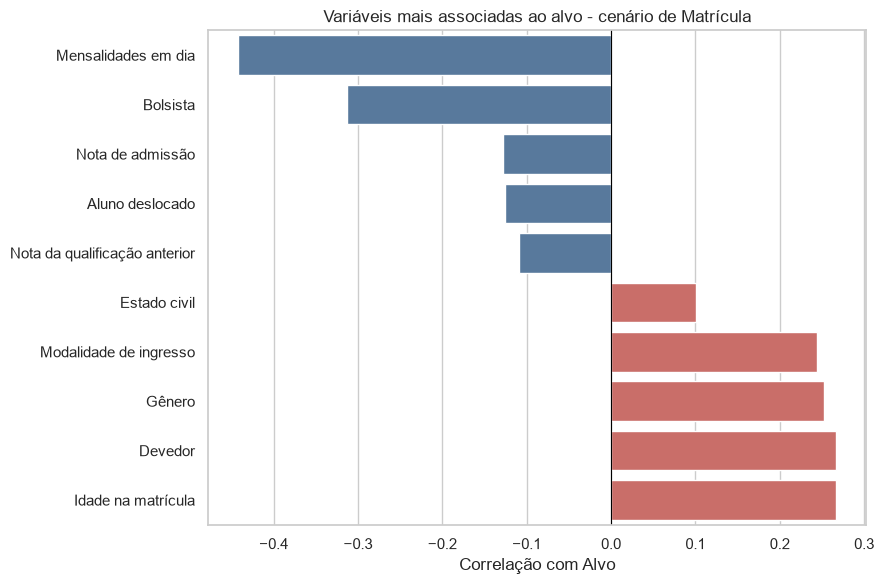

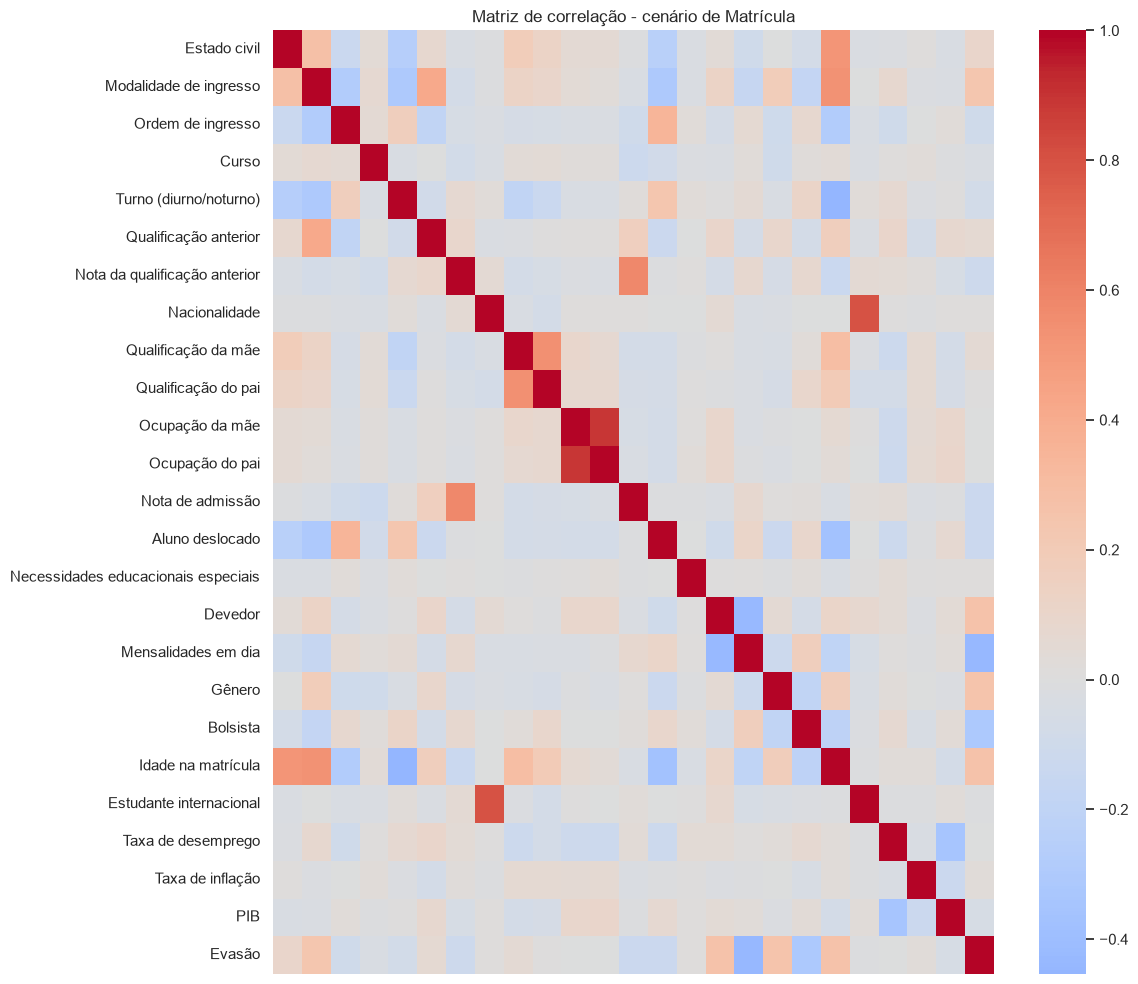

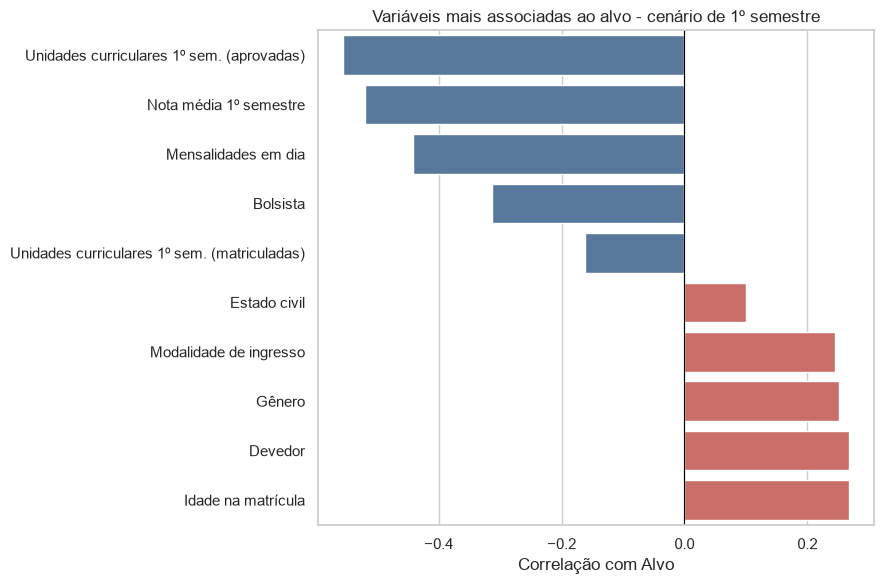

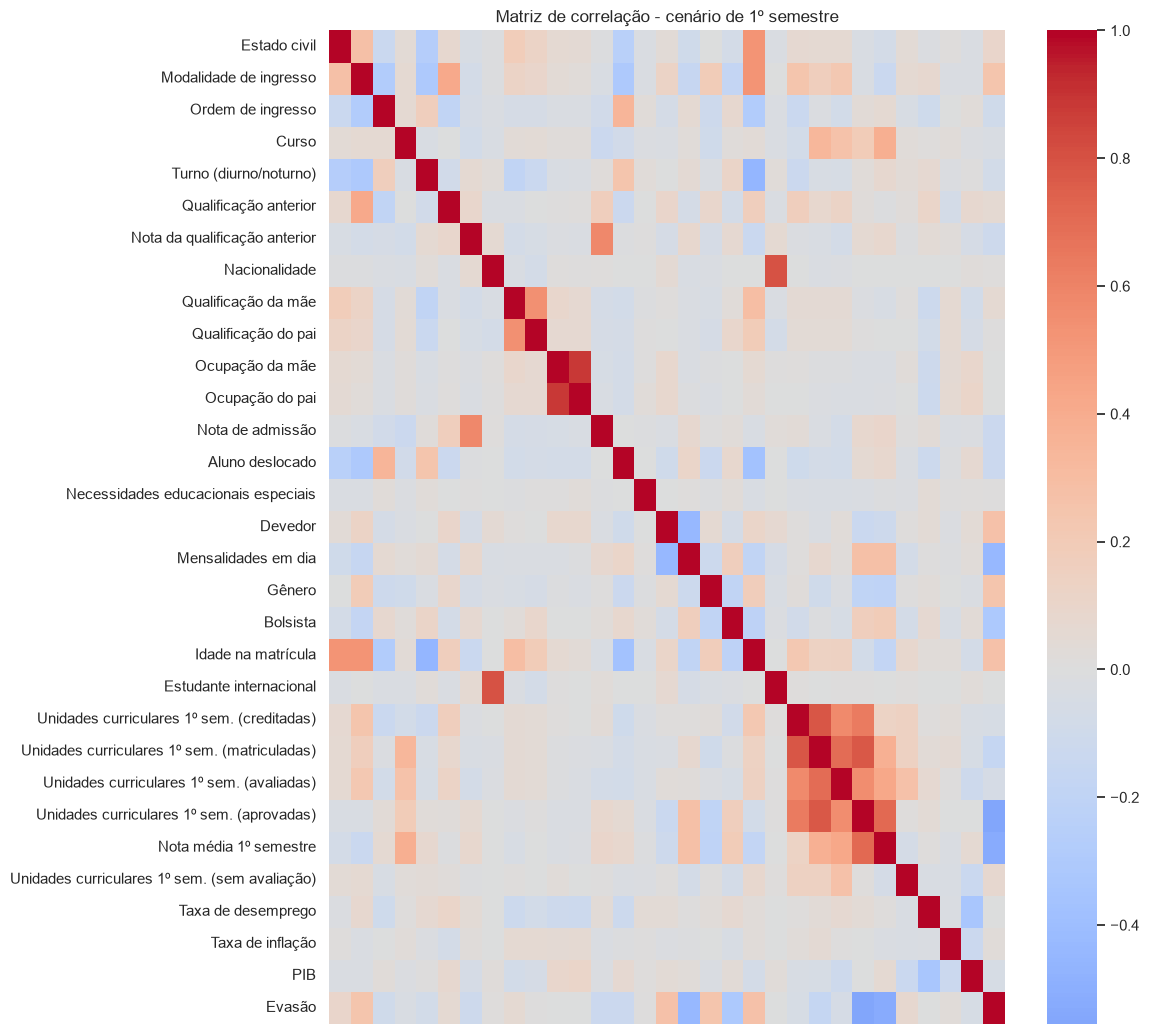

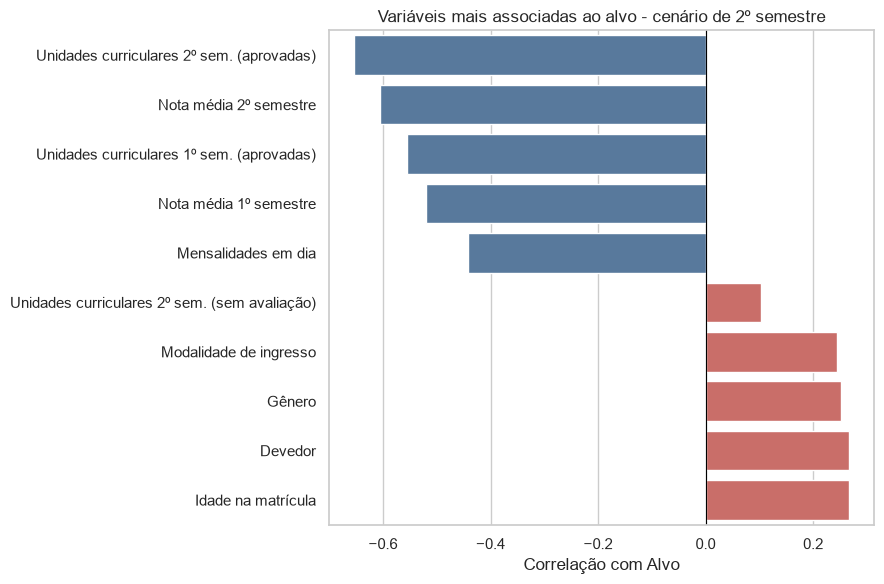

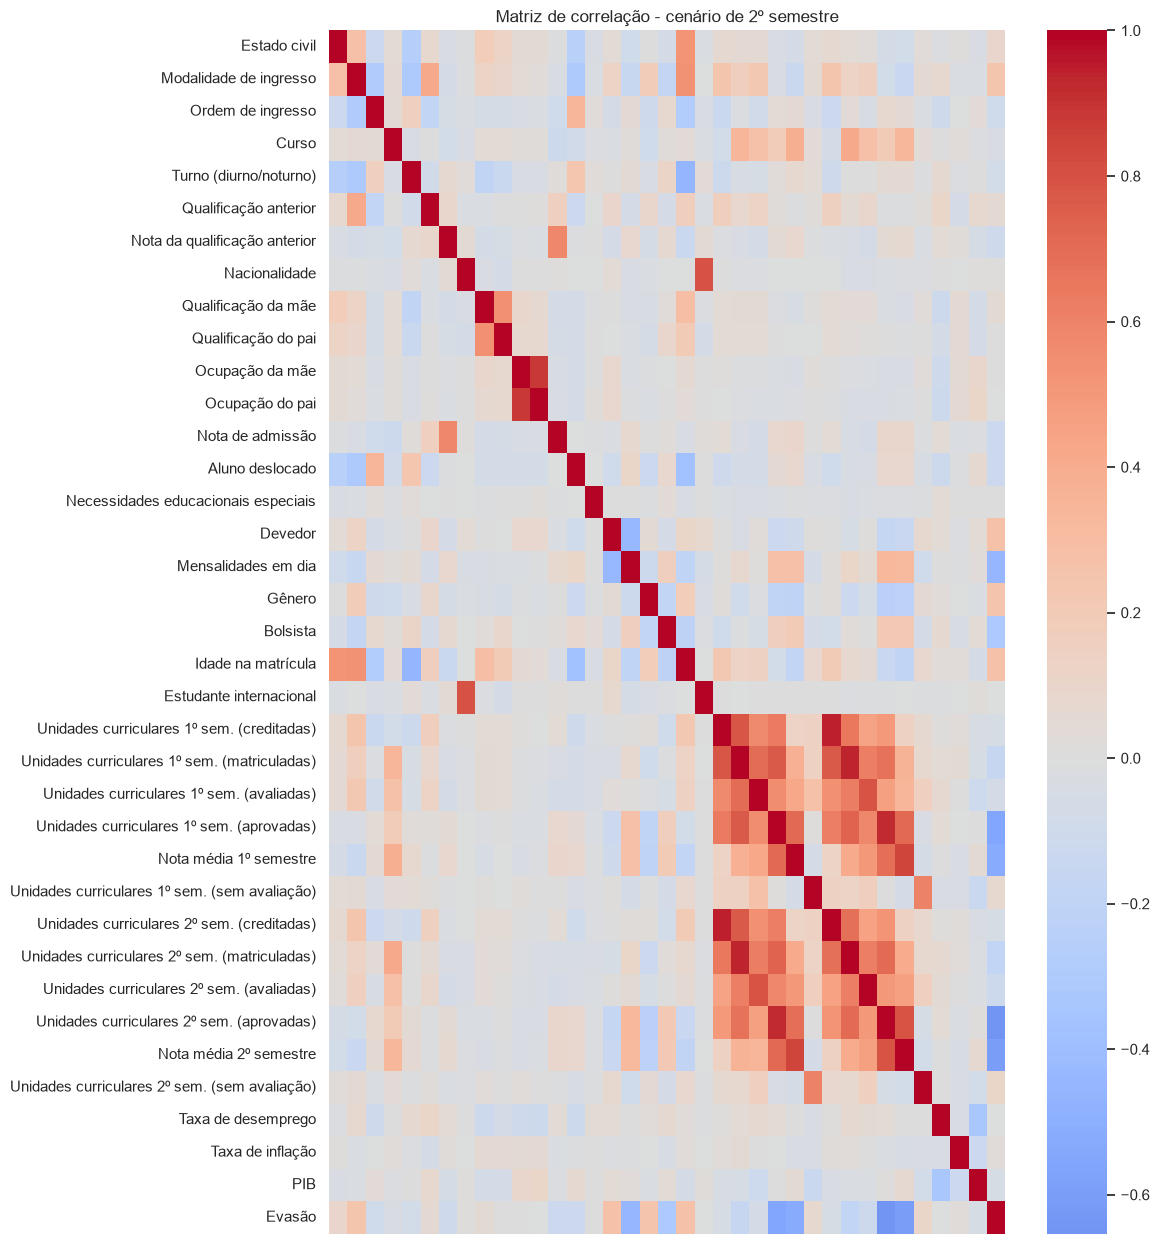

In [12]:
for nome_cenario, features in cenarios.items():
    correlacoes = df[features + ["Alvo"]].corr(numeric_only=True)["Alvo"].drop("Alvo").sort_values()
    top_correlacoes = pd.concat([correlacoes.head(5), correlacoes.tail(5)]).sort_values()
    top_correlacoes.index = top_correlacoes.index.map(
        lambda coluna: nomes_variaveis_pt.get(coluna, coluna)
    )

    plt.figure(figsize=(9, 6))
    sns.barplot(x=top_correlacoes.values, y=top_correlacoes.index,
                hue=top_correlacoes.values > 0, legend=False,
                palette={True: "#d95f59", False: "#4c78a8"})
    plt.axvline(0, color="black", linewidth=0.8)
    plt.title(f"Variáveis mais associadas ao alvo - cenário de {nome_cenario}")
    plt.xlabel("Correlação com Alvo")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

    matriz_correlacao = df[features + ["Alvo"]].corr(numeric_only=True)
    matriz_correlacao.index = matriz_correlacao.index.map(
        lambda coluna: nomes_variaveis_pt.get(coluna, coluna)
    )
    matriz_correlacao.columns = matriz_correlacao.columns.map(
        lambda coluna: nomes_variaveis_pt.get(coluna, coluna)
    )
    plt.figure(figsize=(12, max(10, len(features) * 0.35)))
    sns.heatmap(matriz_correlacao,
                cmap="coolwarm", center=0, xticklabels=False, yticklabels=True)
    plt.title(f"Matriz de correlação - cenário de {nome_cenario}")
    plt.tight_layout()
    plt.show()

### Comentário sobre as correlações

- **O que foi feito:** foram selecionadas as variáveis mais positiva e negativamente associadas ao alvo e geradas matrizes completas para os três cenários.
- **Por que isso foi feito:** comparar os cenários mostra como as associações mudam conforme novas informações acadêmicas ficam disponíveis.
- **Conclusão:** algumas variáveis apresentam associação maior com a evasão, mas **correlação não prova causa**. Os gráficos servem como pistas para a modelagem, não como decisão isolada.

## 3. Treinamento e avaliação

O conjunto de teste é estratificado e o `StandardScaler` é ajustado somente nos dados de treino. O `class_weight='balanced'` aumenta a atenção dada à classe minoritária.

### Como funciona cada modelo

- **Regressão Logística:** calcula a probabilidade de o estudante pertencer a cada classe usando uma combinação das variáveis. É parecida com uma regra de pontuação: quanto maior o risco calculado, maior a chance de prever evasão.
- **Árvore de Decisão:** faz perguntas sequenciais sobre os dados, como “as notas estão abaixo de certo valor?”. Cada resposta leva a um novo ramo até chegar à previsão final.
- **Random Forest:** combina várias árvores de decisão treinadas com diferentes amostras e variáveis. A previsão final é a decisão mais votada entre as árvores, o que tende a aumentar a estabilidade do resultado.

### O que significa cada score

- **Precision (precisão):** entre os estudantes sinalizados como em risco, quantos realmente evadiram. Exemplo: `0,80` significa que 80% dos alertas estavam corretos.
- **Recall (sensibilidade):** entre os estudantes que realmente evadiram, quantos foram encontrados pelo modelo. Exemplo: `0,85` significa que 85% dos casos de evasão foram identificados.
- **F1-score:** combina precision e recall em uma única média. É útil quando queremos equilibrar alertas corretos e a identificação da maior parte dos casos.

Neste projeto, o **recall de evasão** merece atenção especial: deixar de identificar um estudante em risco (falso negativo) pode impedir uma ação preventiva.

In [13]:
modelos = {
    "Regressão Logística": LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE),
    "Árvore de Decisão": DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE, max_depth=8),
    "Random Forest": RandomForestClassifier(class_weight="balanced", n_estimators=300,
                                              random_state=RANDOM_STATE, n_jobs=-1),
}

resultados = []
artefatos = {}
y = df["Alvo"]

for nome_cenario, features in cenarios.items():
    X = df[features].apply(pd.to_numeric, errors="raise")
    X_treino, X_teste, y_treino, y_teste = train_test_split(
        X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
    )
    scaler = StandardScaler()
    X_treino_escalado = scaler.fit_transform(X_treino)
    X_teste_escalado = scaler.transform(X_teste)

    for nome_modelo, modelo_base in modelos.items():
        modelo = modelo_base.__class__(**modelo_base.get_params())
        modelo.fit(X_treino_escalado, y_treino)
        previsoes = modelo.predict(X_teste_escalado)
        resultados.append({
            "Cenário": nome_cenario,
            "Modelo": nome_modelo,
            "Precision (evasão)": precision_score(y_teste, previsoes, zero_division=0),
            "Recall (evasão)": recall_score(y_teste, previsoes, zero_division=0),
            "F1 (evasão)": f1_score(y_teste, previsoes, zero_division=0),
        })
        artefatos[(nome_cenario, nome_modelo)] = {
            "modelo": modelo, "features": features, "y_teste": y_teste,
            "previsoes": previsoes, "matriz": confusion_matrix(y_teste, previsoes),
        }

resultados_df = pd.DataFrame(resultados).sort_values(["Cenário", "Recall (evasão)"], ascending=[True, False])
resultados_df.style.format({
"Precision (evasão)": "{:.3f}", "Recall (evasão)": "{:.3f}", "F1 (evasão)": "{:.3f}"
})

,Cenário,Modelo,Precision (evasão),Recall (evasão),F1 (evasão)
3,1º semestre,Regressão Logística,0.854,0.866,0.860
5,1º semestre,Random Forest,0.867,0.840,0.853
4,1º semestre,Árvore de Decisão,0.840,0.786,0.812
6,2º semestre,Regressão Logística,0.879,0.904,0.891
8,2º semestre,Random Forest,0.908,0.885,0.897
7,2º semestre,Árvore de Decisão,0.860,0.847,0.853
0,Matrícula,Regressão Logística,0.653,0.732,0.690
2,Matrícula,Random Forest,0.708,0.723,0.715
1,Matrícula,Árvore de Decisão,0.650,0.702,0.675


### Comentário sobre o treinamento dos modelos

- **O que foi feito:** diferentes modelos foram treinados e avaliados nos três cenários: matrícula, 1º semestre e 2º semestre.
- **Por que isso foi feito:** comparar modelos e momentos de previsão mostra quando a instituição consegue identificar melhor o risco de evasão.
- **Conclusão:** o quadro produzido permite comparar precision, recall e F1-score. Neste contexto, o recall indica a capacidade de encontrar estudantes que realmente evadiram; já precision indica a proporção de alertas corretos. A escolha do modelo deve considerar o objetivo da instituição, e não apenas um score.

,Cenário,Modelo,Precision (evasão),Recall (evasão),F1 (evasão)
3,1º semestre,Regressão Logística,0.854167,0.866197,0.860140
5,1º semestre,Random Forest,0.866828,0.840376,0.853397
4,1º semestre,Árvore de Decisão,0.839599,0.786385,0.812121
6,2º semestre,Regressão Logística,0.878995,0.903756,0.891204
8,2º semestre,Random Forest,0.908434,0.884977,0.896552
7,2º semestre,Árvore de Decisão,0.859524,0.847418,0.853428
0,Matrícula,Regressão Logística,0.652720,0.732394,0.690265
2,Matrícula,Random Forest,0.708046,0.723005,0.715447
1,Matrícula,Árvore de Decisão,0.650000,0.701878,0.674944


,Precision (evasão),Recall (evasão),F1 (evasão)
Cenário,,,
1º semestre,0.854167,0.866197,0.860140
2º semestre,0.878995,0.903756,0.891204
Matrícula,0.652720,0.732394,0.690265


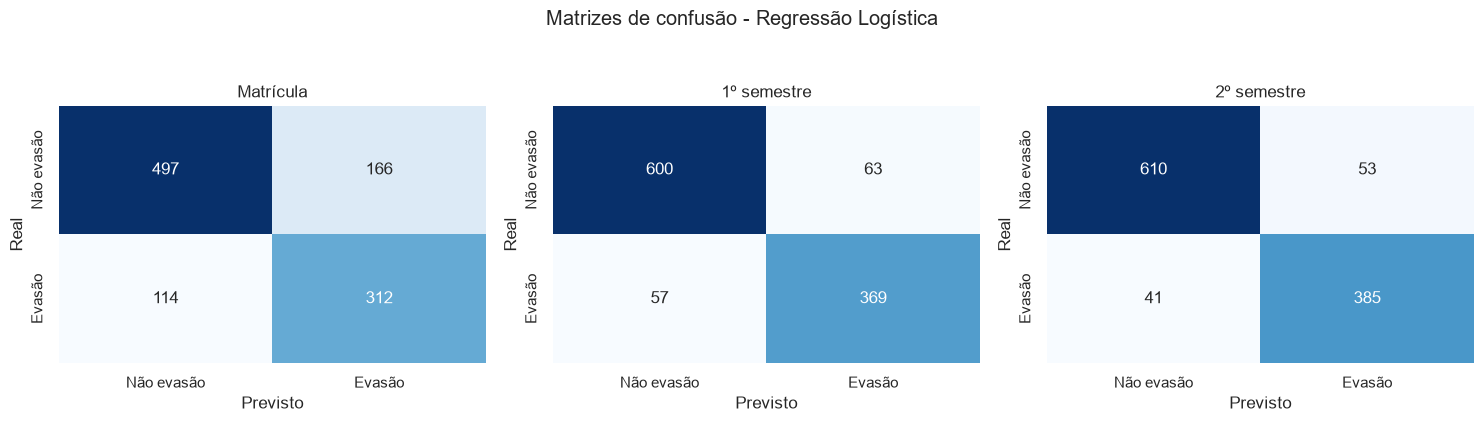

,Precision (evasão),Recall (evasão),F1 (evasão)
Cenário,,,
1º semestre,0.839599,0.786385,0.812121
2º semestre,0.859524,0.847418,0.853428
Matrícula,0.650000,0.701878,0.674944


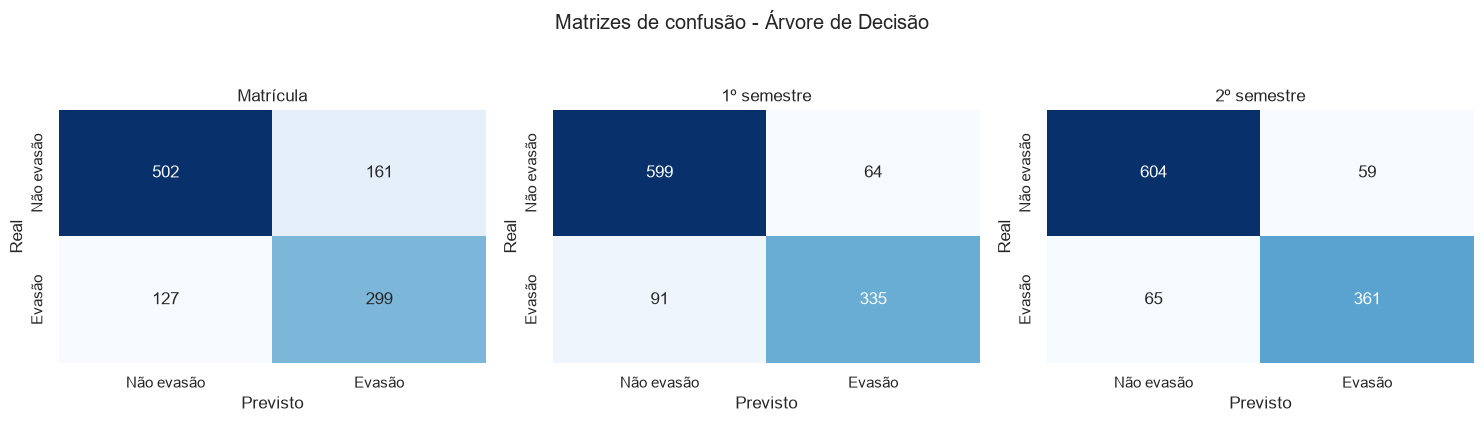

,Precision (evasão),Recall (evasão),F1 (evasão)
Cenário,,,
1º semestre,0.866828,0.840376,0.853397
2º semestre,0.908434,0.884977,0.896552
Matrícula,0.708046,0.723005,0.715447


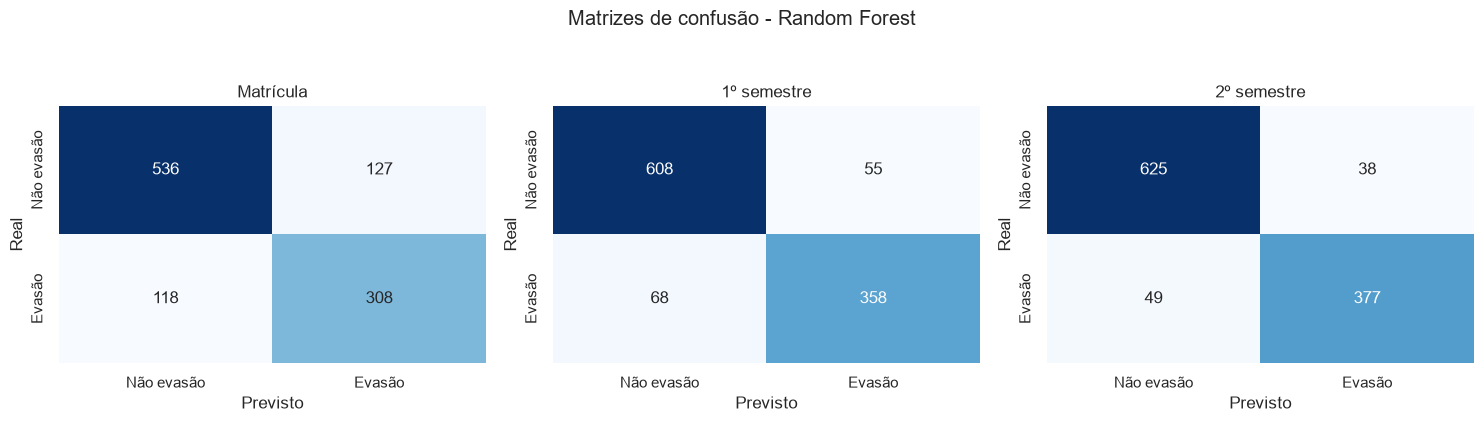

In [14]:
rf_resultados = resultados_df[resultados_df["Modelo"] == "Random Forest"].set_index("Cenário")
display(resultados_df)

for nome_modelo in modelos:
    modelo_resultados = resultados_df[resultados_df["Modelo"] == nome_modelo].set_index("Cenário")
    display(modelo_resultados[["Precision (evasão)", "Recall (evasão)", "F1 (evasão)"]])

    fig, axes = plt.subplots(1, len(cenarios), figsize=(5 * len(cenarios), 4), squeeze=False)
    for ax, nome_cenario in zip(axes[0], cenarios):
        matriz = artefatos[(nome_cenario, nome_modelo)]["matriz"]
        sns.heatmap(
            matriz,
            annot=True,
            fmt="d",
            cmap="Blues",
            cbar=False,
            ax=ax,
            xticklabels=["Não evasão", "Evasão"],
            yticklabels=["Não evasão", "Evasão"],
        )
        ax.set_title(nome_cenario)
        ax.set_xlabel("Previsto")
        ax.set_ylabel("Real")
    fig.suptitle(f"Matrizes de confusão - {nome_modelo}", y=1.05)
    plt.tight_layout()
    plt.show()

### Comentário sobre os modelos

- **O que foi feito:** foram exibidas as métricas e as matrizes de confusão de cada modelo e cenário.
- **Por que isso foi feito:** o recall de evasão mede quantos estudantes realmente em risco foram encontrados; a matriz mostra também falsos positivos e falsos negativos.
- **Conclusão:** o cenário do 2º semestre tende a ter mais informação e, portanto, pode melhorar a identificação do risco. Ainda assim, falsos negativos devem ser observados com atenção, pois representam estudantes em risco que não foram sinalizados.

## 4. Explicabilidade e conclusão

A importância das variáveis indica quais informações mais contribuíram para as decisões do Random Forest no cenário do 1º semestre. Isso apoia a priorização de ações da coordenação, mas não substitui a avaliação humana do estudante.

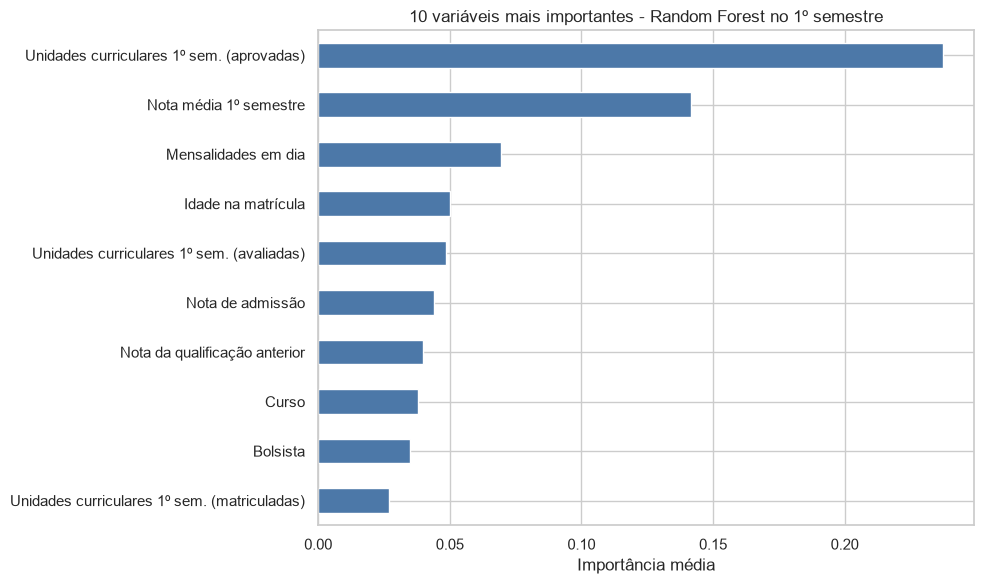

Melhor recall de evasão do Random Forest: 2º semestre (0.885)

Interpretação: o recall deve ser priorizado porque falsos negativos representam estudantes em risco que não receberiam atenção.


In [15]:
artefato_rf = artefatos[("1º semestre", "Random Forest")]
importancias = pd.Series(artefato_rf["modelo"].feature_importances_, index=artefato_rf["features"])
importancias = importancias.sort_values(ascending=False).head(10).sort_values()
importancias.index = importancias.index.map(nomes_variaveis_pt)

plt.figure(figsize=(10, 6))
importancias.plot(kind="barh", color="#4c78a8")
plt.title("10 variáveis mais importantes - Random Forest no 1º semestre")
plt.xlabel("Importância média")
plt.ylabel("")
plt.tight_layout()
plt.show()

melhor = rf_resultados["Recall (evasão)"].idxmax()
print(f"Melhor recall de evasão do Random Forest: {melhor} ({rf_resultados.loc[melhor, 'Recall (evasão)']:.3f})")
print("\nInterpretação: o recall deve ser priorizado porque falsos negativos representam estudantes em risco que não receberiam atenção.")

### Comentário sobre a explicabilidade e a conclusão

- **O que foi feito:** foram listadas as variáveis mais importantes para o Random Forest no cenário do 1º semestre e destacado o melhor recall entre os cenários.
- **Por que isso foi feito:** entender os fatores usados pelo modelo facilita a análise pela coordenação e ajuda a priorizar ações de acompanhamento.
- **Conclusão:** as variáveis mais importantes indicam onde investigar, mas não determinam sozinhas a causa da evasão. O modelo deve apoiar, e não substituir, a avaliação humana e o contato com o estudante.